First the relevant libraries are imported into the notebook

In [1]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
from rdkit.Chem import PandasTools

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set_palette("husl")

from data_profiling import ProfileReport   

Next the data set is loaded and checked to ensure it was imported properly

In [29]:
from rdkit.Chem import PandasTools

df = PandasTools.LoadSDF(
    "data/tox21_10k_data_all.sdf",
    smilesName="smiles",
    molColName="molecule"
)

df.head()

[16:33:21] The 2 defining bonds for an atropisomer are co-planar - atoms are: 4 10
[16:33:21] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[16:33:21] ERROR: Could not sanitize molecule ending on line 21572
[16:33:21] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[16:33:23] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[16:33:23] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[16:33:23] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[16:33:23] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[16:33:23] The 2 defining bonds for an atropisomer are co-planar - atoms are: 4 10
[16:33:25] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[16:33:25] ERROR: Could not sanitize molecule ending on line 446665
[16:33:25] ERROR: Explicit valence for atom # 

,Formula,FW,DSSTox_CID,SR-HSE,ID,smiles,molecule,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,<rdkit.Chem.rdchem.Mol object at 0x12987d770>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,<rdkit.Chem.rdchem.Mol object at 0x12720f3e0>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C47H83NO17,934.1584 (916.1205+18.0379),28909,0,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,<rdkit.Chem.rdchem.Mol object at 0x12720e2d0>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,<rdkit.Chem.rdchem.Mol object at 0x12720d9a0>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,<rdkit.Chem.rdchem.Mol object at 0x12720dd20>,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The dataset is checked for duplicate molecules

In [30]:
unique_smiles = df['smiles'].nunique()
num_smiles = df['smiles'].shape[0]
print(f'Unique SMILES: {unique_smiles}')
print(f'Total SMILES: {num_smiles}')

Unique SMILES: 8041
Total SMILES: 11761


No duplicates were found

In [20]:
#Declare a function for canonicalizing isomeric SMILES
def con_smiles(smile, isomeric:bool=True):
    mol = Chem.MolFromSmiles(smile)
    canonical_smiles = Chem.MolToSmiles(mol, isomericSmiles=isomeric)
    return canonical_smiles

In [21]:
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='smiles', molCol = 'molecule')
df.head()

[16:26:20] WARNING: not removing hydrogen atom without neighbors


,Formula,FW,DSSTox_CID,SR-HSE,ID,smiles,molecule,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,<rdkit.Chem.rdchem.Mol object at 0x1269f6c70>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,<rdkit.Chem.rdchem.Mol object at 0x1269f6ce0>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C47H83NO17,934.1584 (916.1205+18.0379),28909,0,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,<rdkit.Chem.rdchem.Mol object at 0x1269f6dc0>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,<rdkit.Chem.rdchem.Mol object at 0x1269f6e30>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,<rdkit.Chem.rdchem.Mol object at 0x1269f6ea0>,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
#Create and use a function to apply key molecular descriptors to the dataset
def calculate_key_descriptors(mol):
    descriptors = {
        'MolWt': Descriptors.MolWt(mol),
        'LogP' : Descriptors.MolLogP(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'RotBonds' : Descriptors.NumRotatableBonds(mol)
    }
    return descriptors

descriptor_data = []
for row, mol in df['molecule'].items():
    if mol is None:
        desc = {
            'MolWt': np.nan,
            'LogP': np.nan,
            'TPSA': np.nan,
            'NumHDonors': np.nan,
            'NumHAcceptors': np.nan,
            'RotBonds': np.nan
        }
    else:
        desc = calculate_key_descriptors(mol)
    descriptor_data.append(desc)

descriptor_df = pd.DataFrame(descriptor_data, index=df.index)

df_with_descriptors = pd.concat([df, descriptor_df], axis=1)

df_with_descriptors.head()

,Formula,FW,DSSTox_CID,SR-HSE,ID,smiles,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,...,SR-p53,SR-ATAD5,NR-AR-LBD,molecule,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors,RotBonds
0,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0.0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x125aa2f10>,468.992,1.53830,120.85,4,5,0
1,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0.0,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x125aa2810>,691.859,-0.94010,93.40,0,5,2
2,C47H83NO17,934.1584 (916.1205+18.0379),28909,0.0,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x125aa2ff0>,934.171,3.35840,248.08,4,17,13
3,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1.0,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x125aa2ab0>,927.020,3.58460,241.96,4,10,6
4,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x125aa3060>,1342.527,-0.45963,482.13,18,15,32


In [22]:
df_with_descriptors.info()
df_with_descriptors.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11761 entries, 0 to 11760
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Formula        11761 non-null  object 
 1   FW             11761 non-null  object 
 2   DSSTox_CID     11761 non-null  int64  
 3   SR-HSE         8148 non-null   float64
 4   ID             11761 non-null  object 
 5   smiles         11761 non-null  object 
 6   NR-AR          9360 non-null   float64
 7   SR-ARE         7166 non-null   float64
 8   NR-Aromatase   7224 non-null   float64
 9   NR-ER-LBD      8751 non-null   float64
 10  NR-AhR         8167 non-null   float64
 11  SR-MMP         7319 non-null   float64
 12  NR-ER          7695 non-null   float64
 13  NR-PPAR-gamma  8182 non-null   float64
 14  SR-p53         8632 non-null   float64
 15  SR-ATAD5       9089 non-null   float64
 16  NR-AR-LBD      8597 non-null   float64
 17  molecule       11761 non-null  object 
 18  MolWt 

,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors,RotBonds
count,11761.000000,8148.000000,9360.000000,7166.000000,7224.000000,8751.000000,8167.000000,7319.000000,7695.000000,8182.000000,8632.000000,9089.000000,8597.000000,11761.000000,11761.000000,11761.000000,11761.000000,11761.000000,11761.000000
mean,14261.811411,0.052528,0.040598,0.153084,0.049834,0.050966,0.116322,0.156032,0.121767,0.027133,0.062210,0.037188,0.035245,287.301638,2.115182,63.403444,1.341042,3.673667,4.251509
std,11211.380461,0.223103,0.197368,0.360094,0.217617,0.219940,0.320630,0.362911,0.327038,0.162480,0.241551,0.189232,0.184409,167.806879,2.596035,61.765647,2.013709,3.255836,4.372845
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,30.026000,-31.312400,0.000000,0.000000,0.000000,0.000000
25%,3190.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,172.316000,0.927900,26.300000,0.000000,2.000000,1.000000
50%,11903.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,255.280000,2.265020,50.190000,1.000000,3.000000,3.000000
75%,25887.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,356.560000,3.570120,81.190000,2.000000,5.000000,6.000000
max,31685.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1950.681000,22.611800,1095.850000,36.000000,67.000000,47.000000


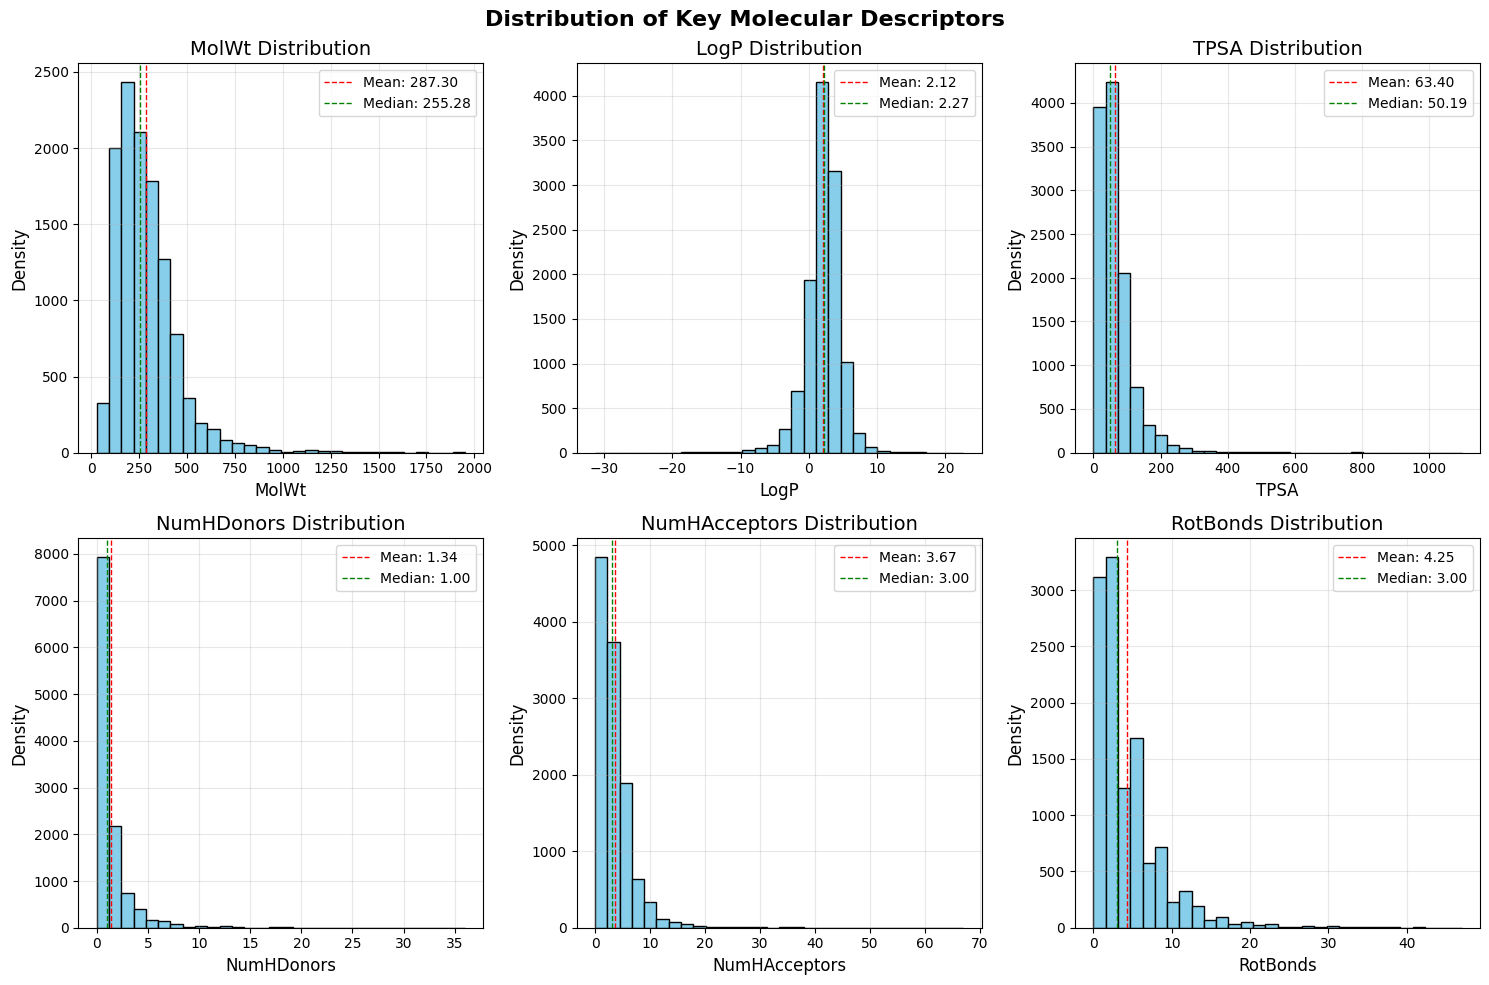

In [23]:
#Plotting key features of the dataset
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Distribution of Key Molecular Descriptors', fontsize=16, fontweight='bold')

descriptors_to_plot = ['MolWt', 'LogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'RotBonds']

for i, descriptor in enumerate(descriptors_to_plot):
    row = i // 3
    col = i % 3

    axes[row, col].hist(df_with_descriptors[descriptor].dropna(), bins=30, color='skyblue', edgecolor='black')

    mean_val = df_with_descriptors[descriptor].mean()
    median_val = df_with_descriptors[descriptor].median()
    axes[row, col].axvline(mean_val, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_val:.2f}')
    axes[row, col].axvline(median_val, color='green', linestyle='dashed', linewidth=1, label=f'Median: {median_val:.2f}')
    axes[row, col].set_title(f'{descriptor} Distribution', fontsize=14)
    axes[row, col].set_xlabel(descriptor, fontsize=12)
    axes[row, col].set_ylabel('Density', fontsize=12)
    axes[row, col].legend()
    axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
#Determining Descriptor Correlations
descriptor_columns = ['MolWt', 'LogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'RotBonds']
correlation_matrix = df_with_descriptors[descriptor_columns].corr()

correlation_matrix

,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors,RotBonds
MolWt,1.000000,0.144018,0.691018,0.524271,0.740054,0.602822
LogP,0.144018,1.000000,-0.426109,-0.376832,-0.322489,0.212811
TPSA,0.691018,-0.426109,1.000000,0.838729,0.901361,0.393356
NumHDonors,0.524271,-0.376832,0.838729,1.000000,0.684649,0.280299
NumHAcceptors,0.740054,-0.322489,0.901361,0.684649,1.000000,0.443571
RotBonds,0.602822,0.212811,0.393356,0.280299,0.443571,1.000000


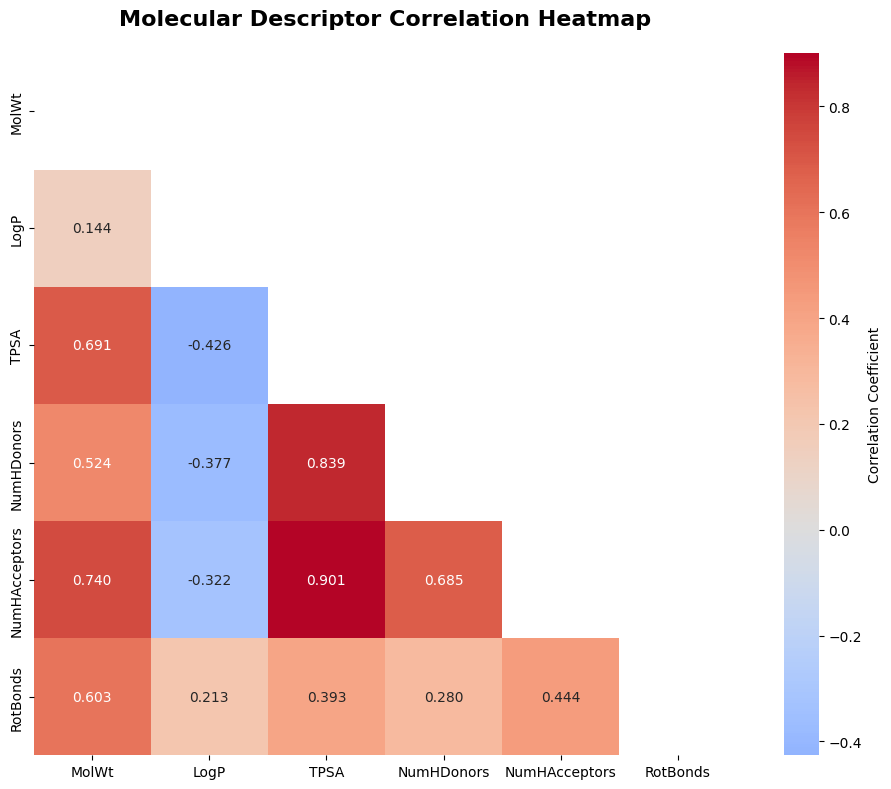

In [25]:
#Ploting a correlation heatmap
plt.figure(figsize=(10, 8))

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True,cmap='coolwarm', center=0, square=True,fmt='.3f',cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Molecular Descriptor Correlation Heatmap', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [26]:
#Generate a report profile
profile = ProfileReport(df_with_descriptors, title="Tox21 Dataset EDA Report", explorative=True)

In [12]:
#Display profile generated report
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 24/24 [00:00<00:00, 74.32it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [32]:
profile.to_file("tox21_eda_report.html")

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]